# Analyse SIMPSON output

This guide is for you if you already have SIMPSON output files (`.spe`, `.fid`, `.xreim`, `.csdf`) and want to plot or process them in Python. **SIMPSON does not need to be installed** for anything on this page.

## The short version

The first cell downloads two example files, the simulated FID and spectrum of ethanol, from the SimPYson repository. Skip it if you are using your own files.

In [1]:
from __future__ import annotations

from pathlib import Path
from urllib.request import urlretrieve

BASE = "https://raw.githubusercontent.com/nuts-org/simpyson/main/examples/read/"
for name in ("ethanol.spe", "ethanol.fid"):
    if not Path(name).exists():
        urlretrieve(BASE + name, name)

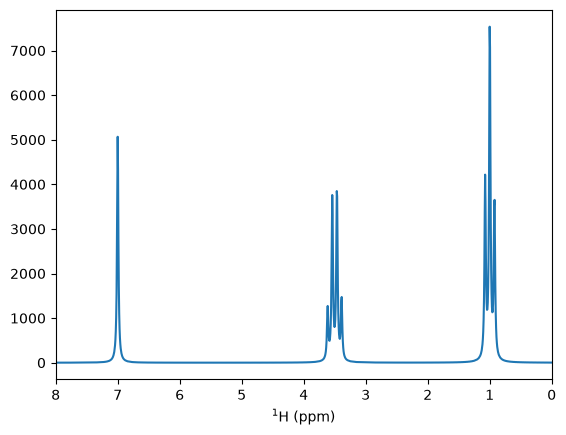

In [ ]:
import matplotlib.pyplot as plt

from simpyson import read_simp

data = read_simp("ethanol.spe", b0="400MHz", nucleus="1H")

plt.plot(data.spe["ppm"], data.spe["real"])
plt.xlim(8, 0)  # NMR convention: ppm decreases to the right
plt.xlabel("$^1$H (ppm)")
plt.show()

[read_simp][simpyson.io.read_simp] reads the file into a [Simpy][simpyson.simpy.Simpy] object. Its `.spe` attribute holds the spectrum as a dictionary with the frequency axis in Hz (`.spe['hz']`) and the intensities `.spe['real']` and `.spe['imag']`. When `b0` and `nucleus` are set, the chemical shift axis is calculated and added as `.spe['ppm']`, see [Chemical shift axis](#chemical-shift-axis).

## File formats

The format is taken from the file extension, or from the `format=` argument if the extension is not the usual one (`read_simp("run1.dat", format="spe")`).

| Extension | Content | Where it ends up in `Simpy` | Notes |
|---|---|---|---|
| `.spe` | Spectrum, as saved by SIMPSON's `fsave` after `fft` | `.spe` | Honours the `REF` line in the header (see below). |
| `.fid` | Time-domain signal | `.fid` | Converted to a spectrum on demand. |
| `.xreim` | Three columns: time, real, imaginary (`fsave -xreim`) | `.xreim` | Not converted to FID or spectrum. |
| `.csdf` | [CSDM](https://csdmpy.readthedocs.io/en/stable/) file | `.spe` | Needs `csdmpy`, which is installed with SimPYson. Any frequency unit in the file is converted to Hz. |

Each attribute is a dictionary of NumPy arrays:

| Attribute | Keys |
|---|---|
| `.fid` | `time` (ms), `real`, `imag`, `np`, `sw` (Hz) |
| `.spe` | `hz` (Hz), `real`, `imag`, `np`, `sw` (Hz), and `ppm` once it has been computed |
| `.ppm` | `ppm`, `real`, `imag` |
| `.xreim` | `time`, `real`, `imag` |

An attribute is `None` when there is no data for it, for example `.ppm` without `b0` and `nucleus`. `print(data)` shows what a `Simpy` object currently holds.

## Reading a FID

Simpy(fid(np=4096, sw=10000 Hz))
4096 points, spectral width 10000 Hz, last time point 409.5 ms


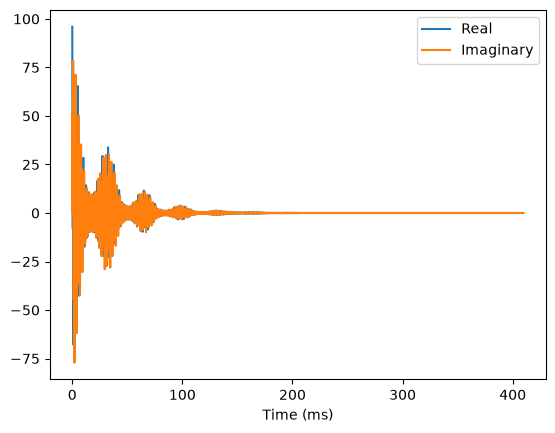

In [3]:
fid_data = read_simp("ethanol.fid")
print(fid_data)
print(
    f"{fid_data.fid['np']:.0f} points, spectral width {fid_data.fid['sw']:.0f} Hz, "
    f"last time point {fid_data.fid['time'][-1]:.1f} ms"
)

plt.plot(fid_data.fid["time"], fid_data.fid["real"], label="Real")
plt.plot(fid_data.fid["time"], fid_data.fid["imag"], label="Imaginary")
plt.xlabel("Time (ms)")
plt.legend()
plt.show()

## Chemical shift axis

SIMPSON spectra are saved on a frequency axis in Hz. To get ppm, `Simpy` needs to know the field and the observed nucleus:

- `b0` is the external magnetic field as a **<sup>1</sup>H larmor frequency** (`"400MHz"`) or in tesla (`"9.4T"`). It is not the Larmor frequency of the observed nucleus, that is worked out from `nucleus`.
- `nucleus` is the observed nucleus, e.g. `"1H"`, `"13C"`, `"27Al"`.

Give them to `read_simp`, or set them on an object you already have. Setting either one recomputes the ppm axis.

Before: None
After:  Simpy(b0='400MHz', nucleus='1H', spe(np=4096, sw=10000 Hz))


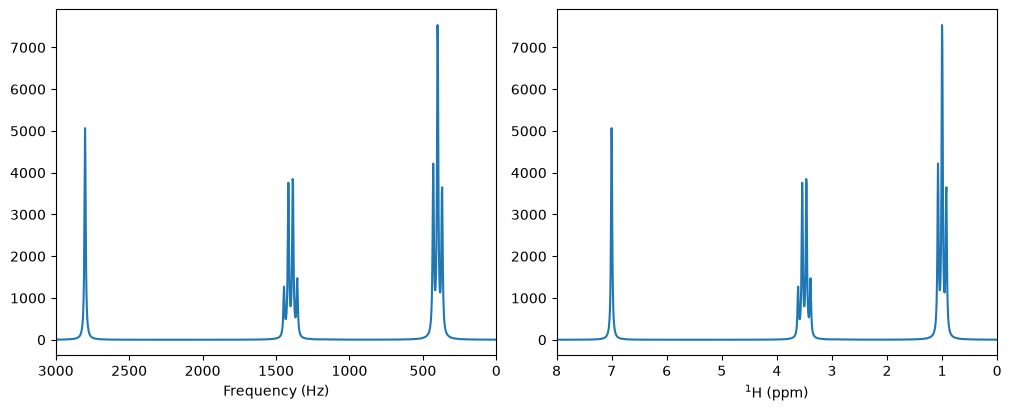

In [ ]:
spe = read_simp("ethanol.spe")
print("Before:", spe.ppm)

spe.b0 = "400MHz"
spe.nucleus = "1H"
print("After: ", spe)

fig, ax = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
ax[0].plot(spe.spe["hz"], spe.spe["real"])
ax[0].set_xlim(3000, 0)
ax[0].set_xlabel("Frequency (Hz)")
ax[1].plot(spe.spe["ppm"], spe.spe["real"])
ax[1].set_xlim(8, 0)
ax[1].set_xlabel("$^1$H (ppm)")
plt.show()

!!! note "The `REF` header"
    A `.spe` file can carry a `REF` value (SIMPSON's `fset $f -ref`). SimPYson applies it, so `hz` already includes it. Simulations written by `simulate_spectrum()` use this to put the centre of the peaks at the middle of the axis.

## FID and spectrum convert automatically

SimPYson converts between the time and frequency domains for you. If you load a FID, the spectrum is available as `.spe`. If you load a spectrum, the FID is available as `.fid`. The conversion happens the first time you access the attribute, so you never call a transform yourself.

| You loaded | You ask for | What happens |
|---|---|---|
| `.fid` | `.spe` | Fast Fourier transform with the zero frequency in the centre of the axis. |
| `.spe` | `.fid` | Inverse transform; `time` is `i / sw` in ms. |
| `.xreim` | `.fid` or `.spe` | Nothing: they stay `None`. |

The conversion is a plain FFT, with no apodisation, zero-filling or phase correction. SIMPSON applies line broadening and zero-filling in the input file's `main` section before saving a `.spe`, so a `.spe` is usually already processed. Below the FID of ethanol is converted and compared with the `.spe` file written by SIMPSON:

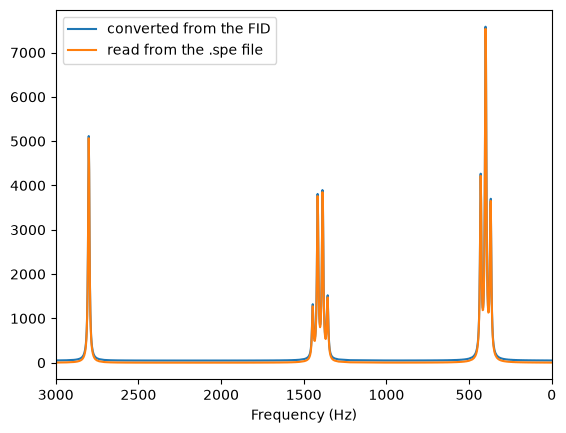

In [ ]:
from_fid = read_simp("ethanol.fid")  # FID -> spectrum
from_file = read_simp("ethanol.spe")

plt.plot(from_fid.spe["hz"], from_fid.spe["real"], label="converted from the FID")
plt.plot(from_file.spe["hz"], from_file.spe["real"], label="read from the .spe file")
plt.xlim(3000, 0)
plt.xlabel("Frequency (Hz)")
plt.legend()
plt.show()

The two agree closely. The small differences, mainly in the baseline, come from the processing SIMPSON applied before saving the `.spe`.

## Exporting

`Simpy.write(filename, format=...)` writes the data to disk and returns the object, so calls can be chained.

| `format` | File content |
|---|---|
| `'csv'` (default) | Two columns with a header: ppm (if `b0` and `nucleus` are set) or Hz, and the real part. For FID-only data, time in ms and real part. |
| `'spe'` | SIMPSON spectrum, readable by SIMPSON and `read_simp`. |
| `'fid'` | SIMPSON FID. |
| `'xreim'` | Three columns: time, real, imaginary. |
| `'csdf'` | CSDM file with the spectrum on an axis in Hz. |

There is no function to write a SIMPSON *input* file from a `Simpy` object. Input files come from [`SimpCalc`][simpyson.calculator.SimpCalc].

In [6]:
spe.write("ethanol_export.csv", format="csv")
spe.write("ethanol_export.spe", format="spe")
spe.write("ethanol_export.csdf", format="csdf")

print(Path("ethanol_export.csv").read_text().splitlines()[:3])
print(read_simp("ethanol_export.csdf"))

['ppm,Real', '-1.249999999999999822e+01,1.800608469999999961e-01', '-1.249389648437499822e+01,1.903272510000000028e-01']
Simpy(spe(np=4096, sw=10000 Hz))


## Graphical user interface

SimPYson includes a GUI for quick inspection and simple conversions. Start it from a terminal:

```bash
simpyson gui
```

or open a file directly:

```bash
simpyson gui path/to/file.spe
```

In the GUI you can view FIDs and spectra, apply basic processing (line broadening, phase correction) and export to the formats above.